# 2.05 · Law of Large Numbers and Central Limit Theorem

Two theorems explain why so much of this tutorial works. The **Law of Large Numbers** says that averages of many
repeats settle down, which is why a crowd of samples can stand in for a posterior and why its error shrinks like
$1/\sqrt N$. The **Central Limit Theorem** says that a sum of many small independent errors is close to Gaussian,
which is why Gaussian noise models are so often reasonable, and why posteriors become Gaussian once there are many
data. Both theorems have conditions, and this notebook also shows what happens when they fail: heavy-tailed noise
and the coloured (correlated) noise of real GPS time series.

**Words this notebook defines:** sample mean, standard error, Law of Large Numbers, Monte Carlo error, effective
sample size, Central Limit Theorem, skewness, heavy tails, white noise, flicker (1/f) noise, Bernstein-von Mises.

**Before this:** [2.03](2-03_probability_distributions.ipynb). · **You will be able to:** predict how the error of an average shrinks with N and when it
does not (heavy tails, correlated noise); use the standard error and the effective sample size; say when a posterior
becomes Gaussian with more data. · **Optional sections:** 6 (Bernstein-von Mises) on a first reading.

**Problems in this notebook**

| example | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| averaging daily GPS positions (sections 1, 5) | 1 (a position or a rate) | 10 to 2000 days | $d_i = m + e_i$ (or $m_1 + m_2 t_i$) | linear |
| estimating a probability by counting draws (section 2) | 1 probability | 10 to 10⁶ draws | none | – |
| sums of independent errors (sections 3-4) | – | – | none | – |
| afterslip time constant τ from N daily data (section 6) | 1 | 2 to 100 | $u = a\log(1 + t/\tau)$ | nonlinear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import bayeskit as bk
from bayeskit import style as S

rng = np.random.default_rng(3)
C1, C2, C3, C4 = S.BLUE, S.ORANGE, S.AQUA, S.VIOLET

## 1. The Law of Large Numbers: averages settle down

**In plain words.** One day's GPS position is off by a few millimetres in an unpredictable direction. Average many
days and the errors largely cancel, so the average settles on the true position. How fast? The scatter of the average
shrinks like one over the square root of the number of days: four times as many days for half the error.

**Precisely.** For independent draws $x_1, \dots, x_N$ with mean $\mu$ and finite variance $\sigma^2$, the sample mean
$\bar x_N = \frac1N\sum x_i$ converges to $\mu$ (Law of Large Numbers; Bernoulli), and
$$\mathrm{Var}[\bar x_N] = \frac{\sigma^2}{N}, \qquad \text{standard error} = \frac{\sigma}{\sqrt N}.$$

saved figures/2-05_lln.png


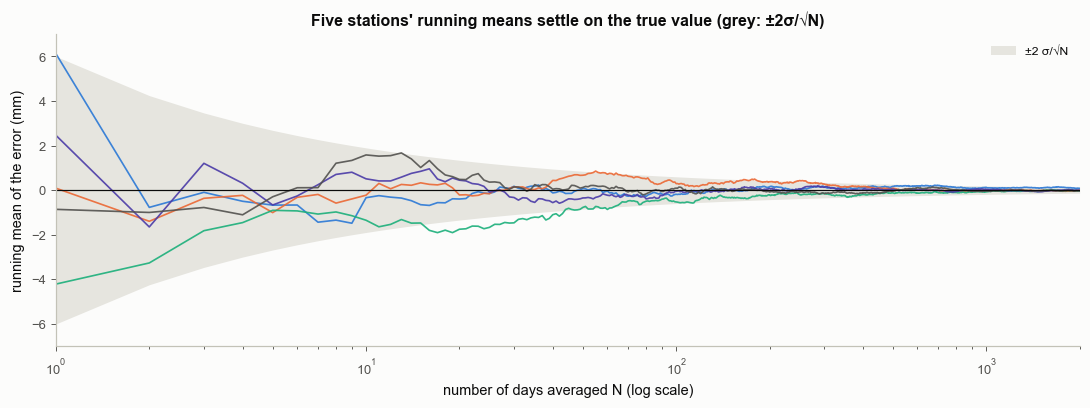

In [2]:
SIG = 3.0                                                     # daily position scatter, mm
Nmax = 2000
nn = np.arange(1, Nmax + 1)
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, col in enumerate(S.CHAINS + [S.INK2]):
    x = SIG * rng.standard_normal(Nmax)
    ax.plot(nn, np.cumsum(x) / nn, color=col, lw=1.1, alpha=0.9)
ax.fill_between(nn, -2 * SIG / np.sqrt(nn), 2 * SIG / np.sqrt(nn), color="#e6e5df", lw=0, zorder=0, label="±2 σ/√N")
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xscale("log"); ax.set_ylim(-7, 7); ax.set_xlim(1, Nmax)
ax.set_xlabel("number of days averaged N (log scale)"); ax.set_ylabel("running mean of the error (mm)")
ax.set_title("Five stations' running means settle on the true value (grey: ±2σ/√N)")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-05_lln")
plt.show()

**How to read it.** Each line is one simulated station's running average of daily errors. Early on the averages
wander widely; as days accumulate they all close in on zero (the true error of the mean). The grey band, of
half-width $2\sigma/\sqrt N$, is where a running mean lies about 95 % of the time *at each N*; a station can stray
outside it for a while (the green line between roughly 15 and 100 days) and still converge.

**Worked example.** Average N = 25 daily positions with σ = 3 mm.
1. standard error $= \sigma/\sqrt N$;
2. repeat the experiment 1000 times and measure the scatter of the 1000 averages.

In [3]:
N25 = 25
means = (SIG * rng.standard_normal((1000, N25))).mean(1)
print(f"step 1: standard error = {SIG} / sqrt({N25}) = {SIG / np.sqrt(N25):.3f} mm")
print(f"step 2: sd of 1000 repeated 25-day averages = {means.std(ddof=1):.3f} mm")

step 1: standard error = 3.0 / sqrt(25) = 0.600 mm
step 2: sd of 1000 repeated 25-day averages = 0.609 mm


**Common misreadings.**
* "After a lucky streak the average must come back down" (the gambler's fallacy). The LLN does not push later draws
  to compensate; earlier deviations are simply diluted by more data.
* "The error falls like $1/N$." It falls like $1/\sqrt N$ for independent errors, and more slowly than that for
  correlated ones (sections 2 and 5).

## 2. Monte Carlo error, and what correlated draws cost

**In plain words.** Every sampler in this tutorial answers questions by counting over its draws ("what share of the
crowd has slip above 2 m?"). The LLN says the count converges, with an error shrinking like $1/\sqrt N$. If successive
draws are correlated, as in any *Markov chain* (a sequence in which each draw is made from the one before, which is
how most samplers work, 2.16), each new draw carries less new information, and the error behaves as if you had fewer
draws: the **effective sample size** (ESS).

**Precisely.** Estimating a probability $p$ by the share $\hat p$ of $N$ independent draws gives
$\mathrm{sd}[\hat p] = \sqrt{p(1-p)/N}$. Take a chain whose statistics do not change along it (*stationary*) and in
which each value is $\varphi$ times the previous one plus fresh independent noise (an *AR(1)* chain; $\varphi$ is the
lag-1 *autocorrelation*, the correlation of each draw with the one before). The variance of its mean is inflated by
$(1+\varphi)/(1-\varphi)$, i.e. $N_\text{eff} = N(1-\varphi)/(1+\varphi)$.

saved figures/2-05_mc_error.png


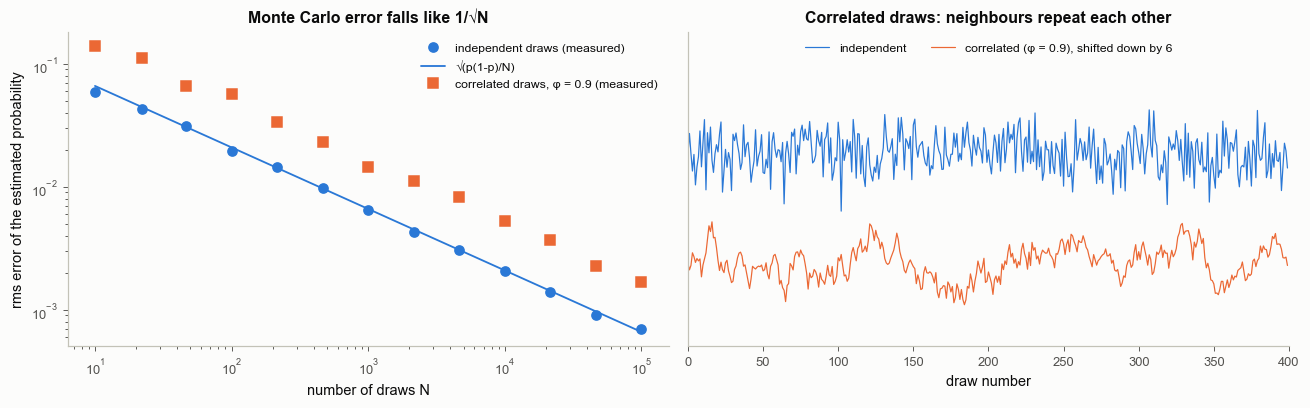

slope of the independent-draw error on log-log axes: -0.49 (theory -0.5)
correlated / independent error for N >= 1000: 2.54


In [4]:
p_true = 2 * stats.norm.sf(2.0)                               # P(|error| > 4 mm) when sigma = 2 mm (2.03)
Ns = np.unique(np.round(np.logspace(1, 5, 13)).astype(int))
phi = 0.9


def ar1(n, phi, rng, nrep):
    """Stationary AR(1) series with unit marginal variance (successive draws correlated by phi)."""
    x = np.empty((nrep, n))
    x[:, 0] = rng.standard_normal(nrep)
    e = rng.standard_normal((nrep, n)) * np.sqrt(1 - phi ** 2)
    for i in range(1, n):
        x[:, i] = phi * x[:, i - 1] + e[:, i]
    return x


err_iid, err_ar = [], []
NREP = 300
for N in Ns:
    xi = rng.standard_normal((NREP, N))
    err_iid.append(np.sqrt(np.mean(((np.abs(xi) > 2).mean(1) - p_true) ** 2)))
    xa = ar1(N, phi, rng, NREP)
    err_ar.append(np.sqrt(np.mean(((np.abs(xa) > 2).mean(1) - p_true) ** 2)))
err_iid, err_ar = np.array(err_iid), np.array(err_ar)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axs[0]
ax.loglog(Ns, err_iid, "o", color=C1, label="independent draws (measured)")
ax.loglog(Ns, np.sqrt(p_true * (1 - p_true) / Ns), color=C1, lw=1.2, label="√(p(1-p)/N)")
ax.loglog(Ns, err_ar, "s", color=C2, label=f"correlated draws, φ = {phi} (measured)")
ax.set_xlabel("number of draws N"); ax.set_ylabel("rms error of the estimated probability")
ax.set_title("Monte Carlo error falls like 1/√N")
ax.legend(fontsize=8)
ax = axs[1]
xa1 = ar1(400, phi, rng, 1)[0]
xi1 = rng.standard_normal(400)
ax.plot(xi1, color=C1, lw=0.8, label="independent")
ax.plot(xa1 - 6, color=C2, lw=0.8, label=f"correlated (φ = {phi}), shifted down by 6")
ax.set_xlabel("draw number"); ax.set_yticks([]); ax.set_xlim(0, 400); ax.set_ylim(-10.5, 6.5)
ax.set_title("Correlated draws: neighbours repeat each other")
ax.legend(fontsize=8, loc="upper center", ncol=2)
fig.tight_layout()
bk.savefig(fig, "2-05_mc_error")
plt.show()
ratio = np.median(err_ar[Ns >= 1000] / err_iid[Ns >= 1000])
print(f"slope of the independent-draw error on log-log axes: {np.polyfit(np.log(Ns), np.log(err_iid), 1)[0]:.2f} (theory -0.5)")
print(f"correlated / independent error for N >= 1000: {ratio:.2f}")

**How to read it.** Left: on log-log axes the error of a counted probability falls along a line of slope $-1/2$
(printed), and correlated draws sit on a parallel line higher up. Right: why: in a correlated chain, neighbouring
draws are nearly the same, so 400 of them contain far fewer independent pieces of information.

Note that the error inflation for a *probability* (a threshold count) is not exactly the
$\sqrt{(1+\varphi)/(1-\varphi)}$ derived for a mean, because thresholding changes the correlation; the measured ratio is
printed above, and the theory value for a mean follows below.

**Worked example.** How many draws are needed to estimate $p$ = P(|error| > 2σ) to 1 % relative precision?
1. independent draws: solve $\sqrt{p(1-p)/N} = 0.01\,p$ for $N$;
2. an AR(1) chain with $\varphi$ = 0.9, for a *mean*: multiply by $(1+\varphi)/(1-\varphi)$.

In [5]:
N_need = (1 - p_true) / (p_true * 0.01 ** 2)
infl = (1 + phi) / (1 - phi)
print(f"p = {p_true:.4f}")
print(f"step 1: N = (1 - p) / (p * 0.01^2) = {N_need:,.0f} independent draws")
print(f"step 2: inflation (1 + phi)/(1 - phi) = {infl:.1f}  ->  about {N_need * infl:,.0f} correlated draws for the same precision of a mean")

p = 0.0455
step 1: N = (1 - p) / (p * 0.01^2) = 209,779 independent draws
step 2: inflation (1 + phi)/(1 - phi) = 19.0  ->  about 3,985,800 correlated draws for the same precision of a mean


**Common misreadings.**
* "10,000 MCMC (Markov chain Monte Carlo) samples are 10,000 samples." Their worth is the effective sample size
  (notebooks 2.16 and 2.19 compute it for real chains).
* "Monte Carlo error vanishes quickly." Halving it costs four times the draws.

**In geodesy.** Every posterior mean and standard deviation reported from a sampler carries this Monte Carlo error on
top of the posterior uncertainty itself; ESS tells you its size.

## 3. The Central Limit Theorem: why so much noise is Gaussian

**In plain words.** Add up many small, independent errors of almost any shape, and the total has a bell-shaped
distribution. A daily GPS position error is such a sum: multipath, troposphere, orbit, clock and antenna errors, each
with its own odd shape. The total is close to Gaussian even though none of its parts is. The convergence is fast for
symmetric parts and slower for skewed ones.

**Precisely.** For independent draws with mean $\mu$ and finite variance $\sigma^2$ (Lindeberg-Lévy),
$$\frac{\sqrt n\,(\bar x_n - \mu)}{\sigma} \;\longrightarrow\; N(0, 1) \quad (n \to \infty).$$
The Berry-Esseen bound says the error in the cdf is at most a constant times $\mathbb E\lvert x-\mu\rvert^3/(\sigma^3\sqrt n)$:
skewed, heavy-shouldered parts converge more slowly. The skewness of a mean of $n$ exponential draws is $2/\sqrt n$.

saved figures/2-05_clt.png


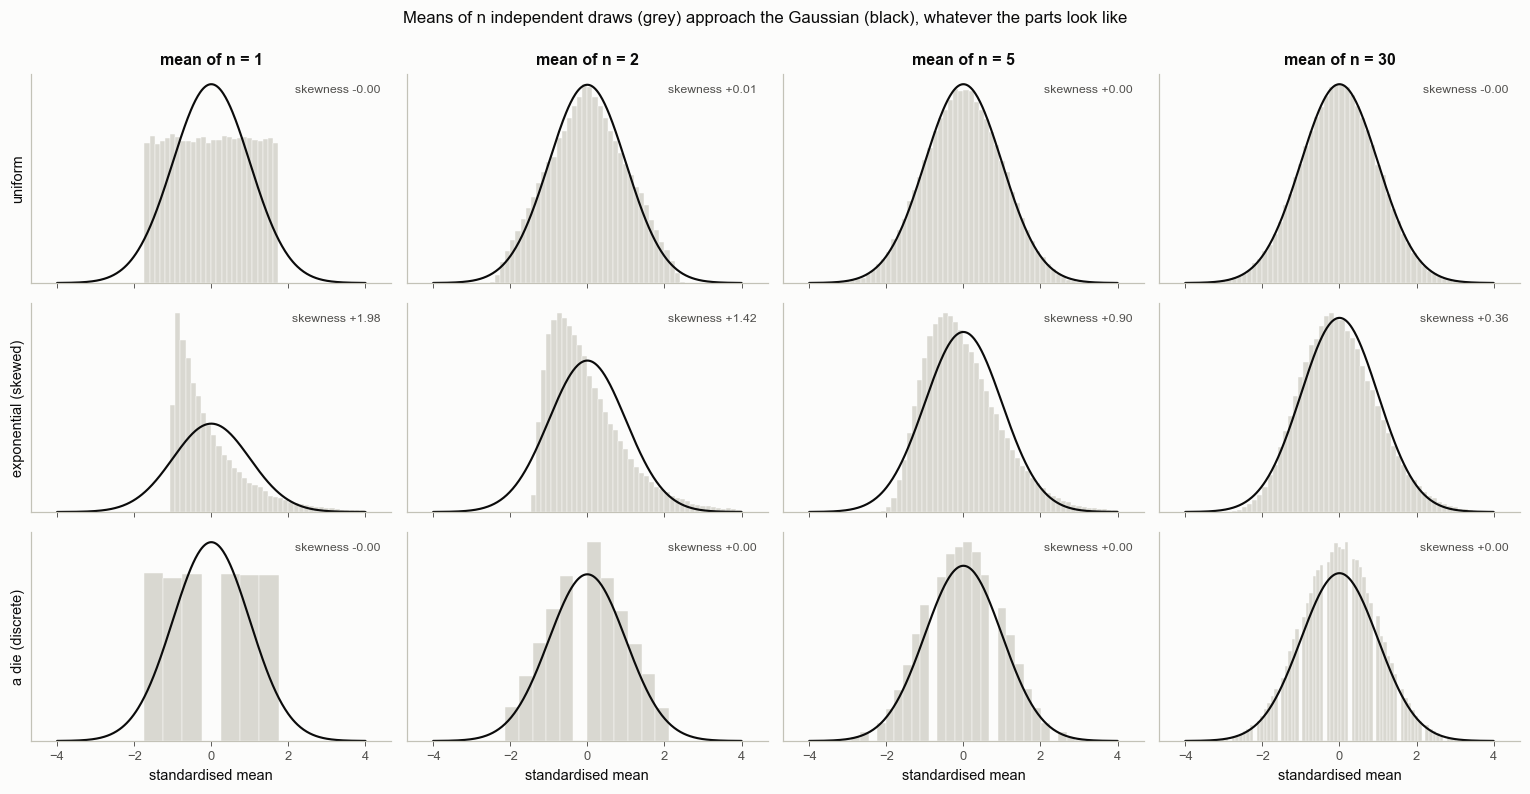

measured skewness of the standardised mean, n = 1, 2, 5, 30:
  uniform                -0.003  +0.006  +0.000  -0.002
  exponential (skewed)   +1.977  +1.420  +0.903  +0.357
  a die (discrete)       -0.002  +0.004  +0.001  +0.005
theory for the exponential, 2/sqrt(n): +2.000  +1.414  +0.894  +0.365


In [6]:
srcs = {"uniform": (lambda size: rng.uniform(-1, 1, size), 0.0, np.sqrt(1 / 3)),
        "exponential (skewed)": (lambda size: rng.exponential(1.0, size), 1.0, 1.0),
        "a die (discrete)": (lambda size: rng.integers(1, 7, size).astype(float), 3.5, np.sqrt(35 / 12))}
ns = [1, 2, 5, 30]
zz = np.linspace(-4, 4, 400)
fig, axs = plt.subplots(3, 4, figsize=(14, 7.2), sharex=True)
skew_tab = {}
for i, (name, (draw, mu, sd)) in enumerate(srcs.items()):
    skew_tab[name] = []
    for j, n in enumerate(ns):
        z = (draw((100_000, n)).mean(1) - mu) / (sd / np.sqrt(n))
        ax = axs[i, j]
        bins = np.arange(-4.25, 4.26, 0.5 / np.sqrt(n)) if name.startswith("a die") else np.linspace(-4, 4, 61)
        ax.hist(z, bins=bins, density=True, color="#d9d8d1", edgecolor=S.SURFACE, lw=0.3)
        ax.plot(zz, stats.norm.pdf(zz), color=S.INK, lw=1.4)
        sk = stats.skew(z)
        skew_tab[name].append(sk)
        ax.text(0.97, 0.95, f"skewness {sk:+.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=S.INK2)
        ax.set_yticks([])
        if i == 0:
            ax.set_title(f"mean of n = {n}", fontsize=10.5)
        if j == 0:
            ax.set_ylabel(name, fontsize=9.5)
for ax in axs[-1]:
    ax.set_xlabel("standardised mean")
fig.suptitle("Means of n independent draws (grey) approach the Gaussian (black), whatever the parts look like", y=0.995, fontsize=11)
fig.tight_layout()
bk.savefig(fig, "2-05_clt")
plt.show()
print("measured skewness of the standardised mean, n = 1, 2, 5, 30:")
for name, v in skew_tab.items():
    print(f"  {name:22s} " + "  ".join(f"{s:+.3f}" for s in v))
print("theory for the exponential, 2/sqrt(n): " + "  ".join(f"{2 / np.sqrt(n):+.3f}" for n in ns))

**How to read it.** Each row starts from a very non-Gaussian shape (flat, one-sided, six discrete values) and the
columns average more and more draws. By $n$ = 5 the symmetric sources are already bell-shaped; the skewed
exponential still leans to one side at $n$ = 5 and is much closer by $n$ = 30, though still slightly skewed
(skewness printed in each panel and above, matching the $2/\sqrt n$ theory).

**Worked example: a GPS error budget.** A daily error made of four independent parts: multipath, uniform on ±3 mm;
troposphere, Laplace with scale 1 mm; orbit, Gaussian with sd 1 mm; antenna, exponential with mean 1 mm (minus its
mean).
1. total variance = sum of the parts' variances (independence): $a^2/3 + 2b^2 + \sigma^2 + \lambda^{-2}$;
2. compare the share of days beyond ±2 sd with the Gaussian value;
3. excess kurtosis, a measure of tail weight (0 for a Gaussian, positive for heavier tails), of the parts and of the
   total.

In [7]:
Nd = 1_000_000
parts = {"multipath (uniform ±3)": rng.uniform(-3, 3, Nd), "troposphere (Laplace b=1)": rng.laplace(0, 1, Nd),
         "orbit (Gaussian 1)": rng.normal(0, 1, Nd), "antenna (exponential, mean removed)": rng.exponential(1, Nd) - 1}
total = sum(parts.values())
var_theory = 3 ** 2 / 3 + 2 * 1 ** 2 + 1 + 1
print(f"step 1: total variance = 3 + 2 + 1 + 1 = {var_theory:.1f} mm^2 -> sd {np.sqrt(var_theory):.3f} mm; simulated sd {total.std():.3f} mm")
print(f"step 2: share beyond +-2 sd: total {np.mean(np.abs(total) > 2 * total.std()):.4f}, Gaussian {2 * stats.norm.sf(2):.4f}")
print("step 3: excess kurtosis:")
for k, v in parts.items():
    print(f"   {k:38s} {stats.kurtosis(v):+.2f}")
print(f"   {'total':38s} {stats.kurtosis(total):+.2f}")

step 1: total variance = 3 + 2 + 1 + 1 = 7.0 mm^2 -> sd 2.646 mm; simulated sd 2.649 mm
step 2: share beyond +-2 sd: total 0.0428, Gaussian 0.0455
step 3: excess kurtosis:
   multipath (uniform ±3)                 -1.20
   troposphere (Laplace b=1)              +2.96
   orbit (Gaussian 1)                     -0.01
   antenna (exponential, mean removed)    +5.97
   total                                  +0.13


**Common misreadings.**
* "The CLT makes every noise Gaussian." Only sums of many *independent* parts with *finite variance*, none of which
  dominates. A single large outlier source is not averaged away (next section).
* "My data are Gaussian because I have many of them." The CLT is about each datum being a sum of many small
  errors, or about averages, not about the number of data.

**In geodesy.** This is the main justification for Gaussian $\mathbf C_d$ in geodetic inversions, and also the
reason to check it: residual histograms with heavy tails point to error sources that are not small and independent.

## 4. When averaging fails: heavy tails

**In plain words.** If extreme values are common enough (very heavy tails), one wild draw can outweigh thousands of
ordinary ones, and the average never settles. The Cauchy distribution is the standard example: the average of a
thousand Cauchy draws is exactly as uncertain as a single draw.

**Precisely.** The Cauchy distribution has no mean and no variance, so neither the LLN nor the CLT applies. The mean
of $n$ independent standard Cauchy draws is again standard Cauchy, for every $n$.

saved figures/2-05_cauchy.png


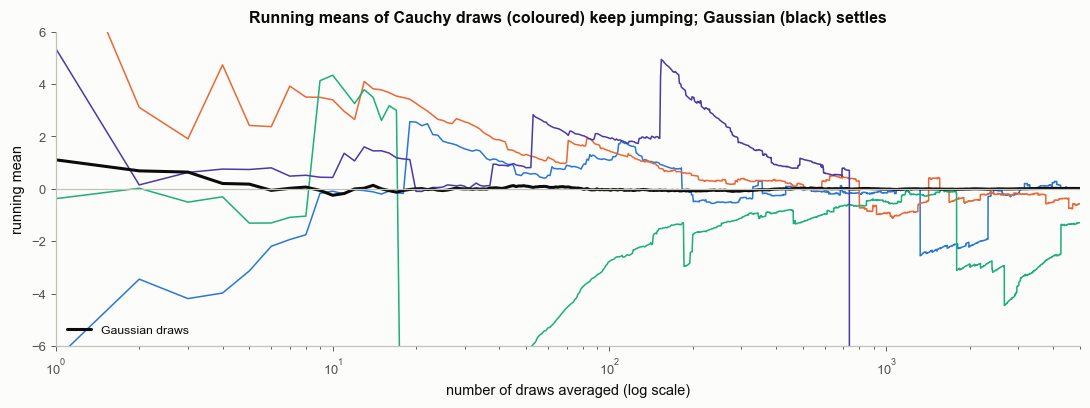

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, col in enumerate(S.CHAINS):
    xc = rng.standard_cauchy(5000)
    ax.plot(np.arange(1, 5001), np.cumsum(xc) / np.arange(1, 5001), color=col, lw=1.0)
xg = rng.standard_normal(5000)
ax.plot(np.arange(1, 5001), np.cumsum(xg) / np.arange(1, 5001), color=S.INK, lw=2.0, label="Gaussian draws")
ax.set_xscale("log"); ax.set_ylim(-6, 6); ax.set_xlim(1, 5000)
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("number of draws averaged (log scale)"); ax.set_ylabel("running mean")
ax.set_title("Running means of Cauchy draws (coloured) keep jumping; Gaussian (black) settles")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-05_cauchy")
plt.show()

**How to read it.** The coloured lines are running means of Cauchy draws: long quiet stretches are interrupted by
jumps whenever one enormous draw arrives, at any stage. The black Gaussian running mean settles as in section 1.

**Worked example.** Measure the spread (interquartile range) of the mean of $n$ Cauchy draws for $n$ = 1, 10, 100,
1000, over 20,000 repeats, and compare with the same quantity for Gaussian draws.

In [9]:
for n in [1, 10, 100, 1000]:
    mc = rng.standard_cauchy((20_000 if n < 1000 else 4000, n)).mean(1)
    mg = rng.standard_normal((20_000 if n < 1000 else 4000, n)).mean(1)
    print(f"n = {n:4d}: IQR of the mean, Cauchy {np.subtract(*np.percentile(mc, [75, 25])):.3f} (theory 2.000) | "
          f"Gaussian {np.subtract(*np.percentile(mg, [75, 25])):.4f} (theory {2 * stats.norm.ppf(0.75) / np.sqrt(n):.4f})")

n =    1: IQR of the mean, Cauchy 2.029 (theory 2.000) | Gaussian 1.3349 (theory 1.3490)
n =   10: IQR of the mean, Cauchy 2.014 (theory 2.000) | Gaussian 0.4278 (theory 0.4266)
n =  100: IQR of the mean, Cauchy 1.999 (theory 2.000) | Gaussian 0.1360 (theory 0.1349)
n = 1000: IQR of the mean, Cauchy 1.939 (theory 2.000) | Gaussian 0.0431 (theory 0.0427)


**Common misreadings.**
* "Just collect more data." With tails this heavy, more data do not help the *mean*; the median does settle, which is
  why robust (L1, Student-t) misfits are used when outliers are present (2.03).

**In geodesy.** Unscreened outliers (antenna changes, snow, multipath events) behave like a heavy tail: a least-squares
fit with them can be pulled arbitrarily far.

## 5. Coloured noise: when √N is too optimistic

**In plain words.** GPS position time series do not have independent daily errors. Part of the error wanders slowly
(motion of the monument the antenna is mounted on, seasonal and atmospheric effects), so today's error is similar to
yesterday's. For such *coloured*
noise, averaging more days helps much less than $1/\sqrt N$ predicts, and the uncertainty of a velocity estimated from
the series is underestimated, often by a large factor, if you assume white (independent) noise (Mao et al. 1999;
Williams 2003).

**Precisely.** A *power spectrum* splits a series' variance by frequency $f$ (slow versus fast wiggles). White noise
has a flat power spectrum. Flicker noise has power proportional to $1/f$: more power at long periods. For white noise the sd of a mean of $N$ days falls as $N^{-1/2}$ and that of a rate fitted over a span $T$
as $T^{-3/2}$; for flicker noise the rate uncertainty falls only as about $T^{-1}$ (both measured below).

saved figures/2-05_coloured_noise.png


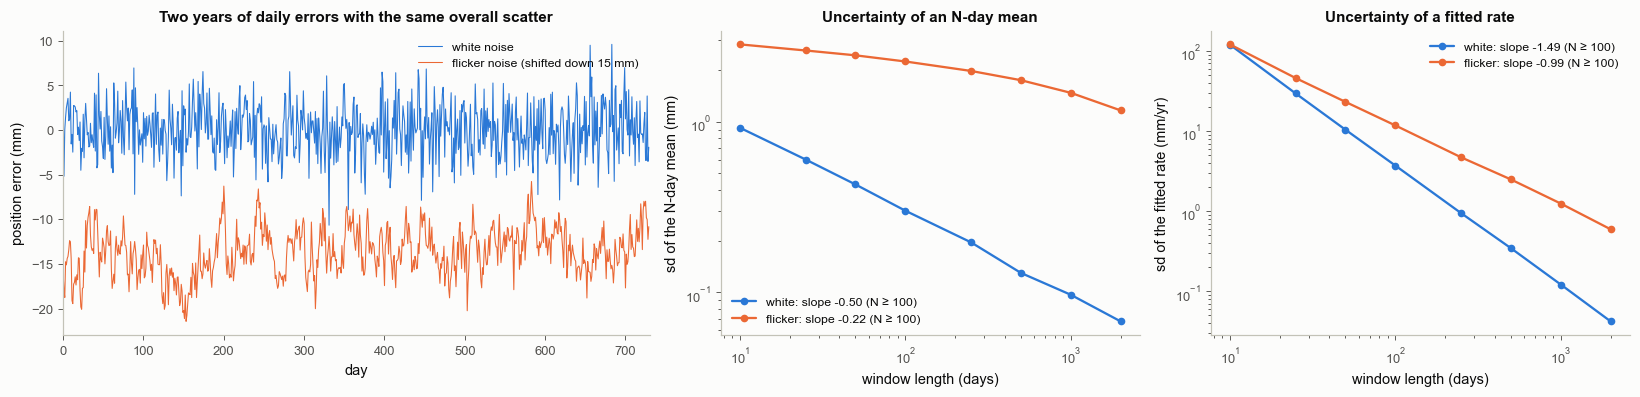

white   : sd of mean over 2000 days 0.068 mm, sd of rate over 2000 days 0.042 mm/yr
flicker : sd of mean over 2000 days 1.165 mm, sd of rate over 2000 days 0.596 mm/yr
flicker / white over 2000 days: mean x17.2, rate x14.1


In [10]:
NT, NREAL = 8192, 600


def flicker(n, rng, nreal):
    """Power-law noise with spectrum 1/f, by spectral synthesis (random phases, amplitude f^-1/2)."""
    f = np.fft.rfftfreq(n)
    amp = np.zeros_like(f)
    amp[1:] = f[1:] ** -0.5
    z = (rng.standard_normal((nreal, f.size)) + 1j * rng.standard_normal((nreal, f.size))) * amp
    return np.fft.irfft(z, n=n, axis=1)


white = rng.standard_normal((NREAL, NT)) * SIG
flick = flicker(NT, rng, NREAL)
flick = flick / flick[:, :2048].std(axis=1, keepdims=True).mean() * SIG   # same scatter within 2048-day windows
Nw = np.array([10, 25, 50, 100, 250, 500, 1000, 2000])
res = {}
for name, X in [("white", white), ("flicker", flick)]:
    sm, sr = [], []
    for N in Nw:
        seg = X[:, :N]
        sm.append(seg.mean(1).std())
        tc = np.arange(N) - (N - 1) / 2
        sr.append(((seg - seg.mean(1, keepdims=True)) @ tc / (tc @ tc)).std() * 365.25)
    res[name] = (np.array(sm), np.array(sr))
fig, axs = plt.subplots(1, 3, figsize=(15, 3.7), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
ax = axs[0]
ax.plot(white[0, :730], color=C1, lw=0.7, label="white noise")
ax.plot(flick[0, :730] - 15, color=C2, lw=0.7, label="flicker noise (shifted down 15 mm)")
ax.set_xlabel("day"); ax.set_ylabel("position error (mm)"); ax.set_xlim(0, 730)
ax.set_title("Two years of daily errors with the same overall scatter", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
for ax, idx, lab, unit, ttl in [(axs[1], 0, "sd of the N-day mean", "mm", "Uncertainty of an N-day mean"),
                                (axs[2], 1, "sd of the fitted rate", "mm/yr", "Uncertainty of a fitted rate")]:
    for name, col in [("white", C1), ("flicker", C2)]:
        v = res[name][idx]
        sel = Nw >= 100
        slope = np.polyfit(np.log(Nw[sel]), np.log(v[sel]), 1)[0]
        ax.loglog(Nw, v, "o-", color=col, ms=4, label=f"{name}: slope {slope:.2f} (N ≥ 100)")
    ax.set_xlabel("window length (days)"); ax.set_ylabel(f"{lab} ({unit})"); ax.legend(fontsize=8)
    ax.set_title(ttl, fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-05_coloured_noise")
plt.show()
for name in ("white", "flicker"):
    sm, sr = res[name]
    print(f"{name:8s}: sd of mean over 2000 days {sm[-1]:.3f} mm, sd of rate over 2000 days {sr[-1]:.3f} mm/yr")
print(f"flicker / white over 2000 days: mean x{res['flicker'][0][-1] / res['white'][0][-1]:.1f}, rate x{res['flicker'][1][-1] / res['white'][1][-1]:.1f}")

**How to read it.** Left: both series have the same overall scatter, but the flicker series wanders in slow
excursions. Middle and right: the uncertainty of the average and of the fitted rate fall much more slowly for flicker
noise (slopes in the legends), so after a few years the white-noise formula understates them by the factors printed
above.

**Worked example.** A 2000-day series of flicker noise, analysed as if the noise were white.
1. white-noise standard error of the mean, $\sigma/\sqrt N$;
2. the actual scatter of 2000-day means under flicker noise (from the 600 simulated series);
3. their ratio: how many times too small the white-noise error bar is.

In [11]:
se_white = SIG / np.sqrt(2000)
print(f"step 1: sigma / sqrt(N) = {SIG} / sqrt(2000) = {se_white:.3f} mm")
print(f"step 2: actual sd of the 2000-day mean under flicker noise = {res['flicker'][0][-1]:.3f} mm")
print(f"step 3: ratio = {res['flicker'][0][-1] / se_white:.1f}")

step 1: sigma / sqrt(N) = 3.0 / sqrt(2000) = 0.067 mm
step 2: actual sd of the 2000-day mean under flicker noise = 1.165 mm
step 3: ratio = 17.4



**Common misreadings.**
* "A long time series makes the velocity error negligible." Only if the noise is white; with flicker noise the rate
  error falls like $1/T$, not $T^{-3/2}$.

**In geodesy.** This is why GPS velocity uncertainties are estimated with power-law noise models, and why a diagonal
$\mathbf C_d$ with daily white-noise σ makes interseismic rates look too precise.

## 6. Bernstein-von Mises: posteriors become Gaussian with enough data

**In plain words.** With few data a posterior can have any shape: skewed, curved, multimodal. With many data that
all constrain the same parameters, the plausible region shrinks so much that, over that small region, the forward
model is nearly linear, and the posterior becomes Gaussian. This is the CLT's cousin for posteriors, and the reason
notebook 2.25 will find its nonlinearity index (how far the forward model departs from a straight line over the plausible
region) falling day by day as afterslip data accumulate.

**Precisely.** Under regularity conditions (a fixed, finite number of parameters; a smooth likelihood; parameters
that are *identifiable*, meaning different values give different predictions; a prior with positive density near the
true value), the posterior approaches $N\big(\hat{\mathbf m},\, \mathbf I(\hat{\mathbf m})^{-1}\big)$ as $N \to \infty$,
where $\hat{\mathbf m}$ is the maximum-likelihood estimate and $\mathbf I$ the *Fisher information*, the expected
curvature of the log-likelihood (how sharply the data pin the parameters down) (Bernstein-von Mises). It can fail when the number of parameters grows with the data (a slip model refined as data
are added) or when the parameter is not identifiable.

Test: afterslip $u(t) = a\log(1 + t/\tau)$ with $a$ = 30 mm known, $\tau$ unknown (true value 3 days), daily data
from day 1 with noise σ = 8 mm, prior $\ln\tau \sim N(\ln 10, 1.2^2)$. Posterior of $\tau$ after $N$ = 2, 5, 20, 100
days, against the Gaussian with the same mean and sd. The non-Gaussianity is measured by the *KL divergence*, a
number that is zero when two distributions are identical and grows as they differ (2.28 explains it).

saved figures/2-05_bvm.png


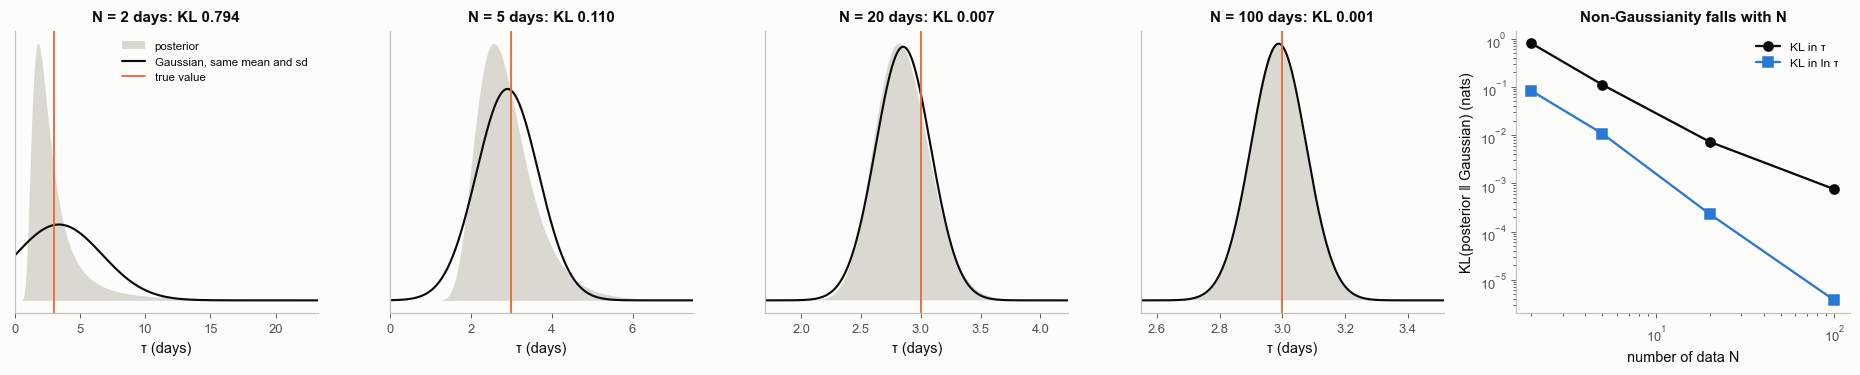

N, KL(posterior || matched Gaussian) in tau and in ln tau (nats):
  N =   2: tau 0.7941   ln tau 0.0823
  N =   5: tau 0.1100   ln tau 0.0107
  N =  20: tau 0.0072   ln tau 0.0002
  N = 100: tau 0.0008   ln tau 0.0000


In [12]:
a_, tau_true, sig_u = 30.0, 3.0, 8.0
t_all = np.arange(1, 101, 1.0)
rng_b = np.random.default_rng(11)
y_all = a_ * np.log1p(t_all / tau_true) + sig_u * rng_b.standard_normal(t_all.size)
tau = np.linspace(0.005, 40, 32000)
dtau = tau[1] - tau[0]
lpri = stats.lognorm(s=1.2, scale=10).logpdf(tau)


def kl_to_matched(p, x, dx):
    mu = (p * x).sum() * dx
    sd = np.sqrt((p * (x - mu) ** 2).sum() * dx)
    q = stats.norm(mu, sd).pdf(x)
    ok = p > 1e-300
    return float(np.sum(p[ok] * np.log(p[ok] / np.maximum(q[ok], 1e-300))) * dx), mu, sd


NS = [2, 5, 20, 100]
fig, axs = plt.subplots(1, 5, figsize=(17, 3.5), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.1]))
kls, kls_log = [], []
for ax, N in zip(axs[:4], NS):
    pred = a_ * np.log1p(t_all[:N][None, :] / tau[:, None])
    lp = lpri - 0.5 * np.sum(((y_all[:N] - pred) / sig_u) ** 2, 1)
    p = np.exp(lp - lp.max()); p /= p.sum() * dtau
    kl, mu, sd = kl_to_matched(p, tau, dtau)
    kls.append(kl)
    lt = np.log(tau); plog = p * tau                          # same posterior as a density in ln tau
    order = np.argsort(lt)
    lt_u = np.linspace(lt.min(), lt.max(), 20000)
    plog_u = np.interp(lt_u, lt[order], plog[order]); plog_u /= plog_u.sum() * (lt_u[1] - lt_u[0])
    kls_log.append(kl_to_matched(plog_u, lt_u, lt_u[1] - lt_u[0])[0])
    lo, hi = max(mu - 5 * sd, 0), mu + 6 * sd
    ax.fill_between(tau, p, color="#d9d8d1", lw=0, label="posterior")
    ax.plot(tau, stats.norm(mu, sd).pdf(tau), color=S.INK, lw=1.4, label="Gaussian, same mean and sd")
    ax.axvline(tau_true, color=C2, lw=1.2, label="true value")
    ax.set_xlim(lo, hi); ax.set_yticks([]); ax.set_xlabel("τ (days)")
    ax.set_title(f"N = {N} days: KL {kl:.3f}", fontsize=10)
axs[0].legend(fontsize=7.5, loc="upper right")
ax = axs[4]
ax.loglog(NS, kls, "o-", color=S.INK, label="KL in τ")
ax.loglog(NS, np.maximum(kls_log, 1e-6), "s-", color=C1, label="KL in ln τ")
ax.set_xlabel("number of data N"); ax.set_ylabel("KL(posterior ‖ Gaussian) (nats)")
ax.set_title("Non-Gaussianity falls with N", fontsize=10); ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-05_bvm")
plt.show()
print("N, KL(posterior || matched Gaussian) in tau and in ln tau (nats):")
for N, k1, k2 in zip(NS, kls, kls_log):
    print(f"  N = {N:3d}: tau {k1:.4f}   ln tau {k2:.4f}")

**How to read it.** With two days the posterior of $\tau$ is skewed with a long right tail, and its matched Gaussian
misplaces the probability. By 20 and 100 days the posterior is narrow and indistinguishable from its Gaussian. The
right panel shows the KL divergence falling; it is smaller when the same posterior is described in $\ln\tau$, because
the logarithm absorbs most of the skew. Describing the same model in different variables is a *reparameterisation*
(2.02 met one for the funnel; 2.11 shows its effect on priors).

**Common misreadings.**
* "Many data, so Gaussian error bars are fine." Only if the *number of parameters* stays fixed while the data grow.
  A slip inversion that adds patches as data are added may never reach this regime for the poorly resolved patches.

**Later in the course.** The day-by-day afterslip example of notebook 2.25 shows this theorem at work: the extended
Kalman filter was biased while the posterior was broad and curved, and accurate once it had narrowed into the
near-linear regime.

## Summary

| statement | requires | fails when | consequence for inversions |
|---|---|---|---|
| LLN: averages converge | finite mean, independence (or weak dependence) | heavy tails (Cauchy) | samplers work: averages over draws converge |
| standard error σ/√N | independent, finite variance | correlated draws or coloured noise | use ESS for chains; power-law noise for GPS rates |
| CLT: sums become Gaussian | many independent parts, finite variance, none dominant | outlier sources | Gaussian $\mathbf C_d$ is reasonable; check residual tails |
| Bernstein-von Mises | fixed number of parameters, smooth identifiable likelihood | parameters grow with data; non-identifiability | posteriors of well-resolved parameters become Gaussian |

Next: [**2.06 · Matrix and notation primer**](2-06_matrix_primer.ipynb).